# Part 5: Feature Selection

Assessment of the impact of feature selection on classification performance, using the Ridge, Lasso
and Elastic Net regularization methods, as required in section 5 of the assignment.

### Contents

1. Background
2. Data preparation
3. The three regularized models
4. Exploring different values of C
5. Choosing C by cross-validation
6. Coefficients and selected variables
7. Full set versus reduced sets
8. Effect of class balancing
9. Discussion
10. References

## 1. Background

Regularization adds a penalty term to the model's loss function. In linear regression the base loss is
the residual sum of squares, and in logistic regression it is the negative log-likelihood. The
penalties are the same in both cases:

| Model | Penalty | `l1_ratio` parameter | Zeroes coefficients |
|---|---|---|---|
| Ridge | λ Σ βⱼ² , L2 norm | 0 | No |
| Lasso | λ Σ \|βⱼ\| , L1 norm | 1 | Yes |
| Elastic Net | mixture of the two | between 0 and 1 | Yes |

From version 1.8 of scikit-learn onwards, the penalty is specified by the `l1_ratio` parameter:
- `l1_ratio` = 0: pure Ridge (only $L_2$).
- `l1_ratio` = 1: pure Lasso (only $L_1$).
- `l1_ratio` = 0.5: a balanced 50/50 mixture.

The strength of the penalty is given by `C`, which is the **inverse of λ**: small values of `C` mean a
strong penalty.

The target is `target_class`, a qualitative variable with three categories. The variable
`target_regression` is the target of the regression task and is therefore excluded from the predictors.

## 2. Data preparation

The data is loaded and the three columns that the exploratory analysis identified as unusable are
removed: `calcium_baseline`, which is constant, `systolic_index`, which duplicates `systolic_bp`, and
`age_normalized`, which is a rescaling of `age`.

The split into training and test sets is **stratified**, which preserves the proportions of the three
classes in both partitions. This matters because class `DI_HT` has only 85 records in total.

Finally, the variables are standardized with `StandardScaler`. This step is mandatory, since the
penalty term is scale-sensitive and, without it, variables with larger values would be penalized more
than the others purely because of their units. The scaler is **fitted on the training set only** and
then applied to the test set, so that no information from the test set influences the model.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (accuracy_score, f1_score, balanced_accuracy_score,
                             recall_score, confusion_matrix, classification_report)

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
pd.set_option('display.float_format', '{:.4f}'.format)
sns.set_theme(style='whitegrid', context='notebook')

RANDOM_STATE = 42
print('scikit-learn:', sklearn.__version__)

file_name = 'dataset_grupo_22.csv'
candidates = [Path.cwd() / file_name, Path.cwd().parent / file_name]
path = next((p for p in candidates if p.is_file()), None)
if path is None:
    raise FileNotFoundError(f'Could not find {file_name}.')

df = pd.read_csv(path)
TARGET_REG, TARGET_CLS = 'target_regression', 'target_class'

# Columns removed based on the exploratory analysis (constant and redundant)
REMOVED = ['calcium_baseline', 'age_normalized', 'systolic_index']

num_cols = [c for c in df.select_dtypes(include='number').columns
            if c not in REMOVED + [TARGET_REG]]
cat_cols = [c for c in df.select_dtypes(exclude='number').columns if c != TARGET_CLS]

# Encoding the categorical variables into binary columns
X = pd.get_dummies(df[num_cols + cat_cols], columns=cat_cols, drop_first=True)
y = df[TARGET_CLS]
columns = list(X.columns)
classes = sorted(y.unique())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)

# Standardization: fitted on the training set, applied to the test set
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print(f'Original variables: {len(num_cols)} numeric + {len(cat_cols)} categorical '
      f'= {len(num_cols) + len(cat_cols)}')
print(f'Columns after get_dummies: {len(columns)}')
print(f'Train: {len(X_train)} | Test: {len(X_test)}')
print('\nClass distribution (train / test, in %):')
print(pd.DataFrame({'train': y_train.value_counts(normalize=True) * 100,
                    'test': y_test.value_counts(normalize=True) * 100}).round(2))

scikit-learn: 1.9.1
Original variables: 18 numeric + 12 categorical = 30
Columns after get_dummies: 40
Train: 1500 | Test: 500

Class distribution (train / test, in %):
               train    test
target_class                
DI_HY        89.8700 90.0000
HT            5.8700  5.8000
DI_HT         4.2700  4.2000


**Conclusions:** 30 original variables remain, 18 numeric and 12 categorical, which after encoding
give rise to 40 columns.

Stratification worked. The proportions of the three classes are practically identical in the training
and test sets, preserving the original imbalance of roughly 90, 6 and 4 per cent.

## 3. The three regularized models

The main parameters of `LogisticRegression` are:

- **`solver='saga'`**, the optimization algorithm, and the only one that supports all three penalties;
- **`l1_ratio`**, which chooses the penalty, with 0 for Ridge, 1 for Lasso and 0.5 for Elastic Net;
- **`C`**, the strength of the regularization, the inverse of λ;
- **`max_iter`**, the maximum number of iterations allowed to the algorithm.

The three models are first fitted with `C = 1`, an intermediate value of the scale, in order to observe
the baseline behaviour before any tuning. Since the classes are imbalanced, *accuracy* is reported, but
also the **macro F1** and the **balanced accuracy**, which give equal weight to the three classes.

In [2]:
MODELS = [('Ridge', 0.0), ('Lasso', 1.0), ('Elastic Net', 0.5)]

def magnitudes(model):
    """Largest absolute coefficient of each column, across the three classes."""
    return np.abs(model.coef_).max(axis=0)

def metrics_of(model, X_scaled, name, extra=None):
    predicted = model.predict(X_scaled)
    result = {'model': name,
              'accuracy': accuracy_score(y_test, predicted),
              'macro F1': f1_score(y_test, predicted, average='macro'),
              'balanced acc': balanced_accuracy_score(y_test, predicted)}
    if extra:
        result.update(extra)
    return result

rows = []
for name, ratio in MODELS:
    model = LogisticRegression(solver='saga', l1_ratio=ratio, C=1.0,
                               max_iter=10000, random_state=RANDOM_STATE)
    model.fit(X_train_scaled, y_train)
    rows.append(metrics_of(model, X_test_scaled, name,
                           {'l1_ratio': ratio, 'C': 1.0,
                            'non-zero': int((magnitudes(model) > 1e-4).sum())}))

pd.DataFrame(rows).set_index('model')[['l1_ratio', 'C', 'accuracy',
                                       'macro F1', 'balanced acc', 'non-zero']]

,l1_ratio,C,accuracy,macro F1,balanced acc,non-zero
model,,,,,,
Ridge,0.0000,1.0000,0.9460,0.6801,0.6539,40
Lasso,1.0000,1.0000,0.9440,0.6579,0.6380,37
Elastic Net,0.5000,1.0000,0.9460,0.6801,0.6539,39


**Conclusions:** With `C = 1`, Ridge and Elastic Net reach 0.9460 *accuracy* and Lasso 0.9440. The
relevant difference lies in the number of non-zero coefficients: Lasso zeroes three of the 40 columns
and Elastic Net one, while Ridge keeps them all. This is exactly the behaviour predicted by the theory.

An *accuracy* above 0.94 looks excellent, but the macro F1 sits between 0.66 and 0.68 and the balanced
accuracy at about 0.65. The gap between these metrics reveals that the model is mostly getting the
majority class right, which confirms how important it is not to assess this problem by *accuracy*
alone.

## 4. Exploring different values of C

To understand the effect of regularization it is necessary to observe how the model behaves across the
whole range of penalties, and not only at an isolated value. Twelve values of `C` are therefore
examined on a logarithmic scale between 0.001 and 100, using Lasso because it is the penalty that
zeroes coefficients.

For each value we record the number of non-zero columns, the number of original variables retained and
the performance on the test set.

In [3]:
C_GRID = np.logspace(-3, 2, 12)

def retained_variables(model, column_names):
    """Converts non-zero columns back into original variables."""
    values = magnitudes(model)
    alive = {column_names[i] for i in range(len(column_names)) if values[i] > 1e-4}
    numeric = [c for c in num_cols if c in alive]
    categorical = [c for c in cat_cols
                   if any(v.startswith(c + '_') for v in alive)]
    return numeric, categorical, len(alive)

path_results = []
for C in C_GRID:
    model = LogisticRegression(solver='saga', l1_ratio=1.0, C=C,
                               max_iter=10000, random_state=RANDOM_STATE)
    model.fit(X_train_scaled, y_train)
    kept_num, kept_cat, n_columns = retained_variables(model, columns)
    predicted = model.predict(X_test_scaled)
    path_results.append({'C': C,
                         'non-zero columns': n_columns,
                         'variables retained': len(kept_num) + len(kept_cat),
                         'accuracy': accuracy_score(y_test, predicted),
                         'macro F1': f1_score(y_test, predicted, average='macro')})

path_results = pd.DataFrame(path_results)
path_results

,C,non-zero columns,variables retained,accuracy,macro F1
0,0.0010,0,0,0.9000,0.3158
1,0.0028,0,0,0.9000,0.3158
2,0.0081,2,2,0.9140,0.4478
3,0.0231,3,3,0.9360,0.5772
4,0.0658,14,13,0.9360,0.5885
5,0.1874,28,21,0.9420,0.6458
6,0.5337,33,24,0.9400,0.6432
7,1.5199,38,29,0.9460,0.6801
8,4.3288,40,30,0.9460,0.6774
9,12.3285,40,30,0.9460,0.6774


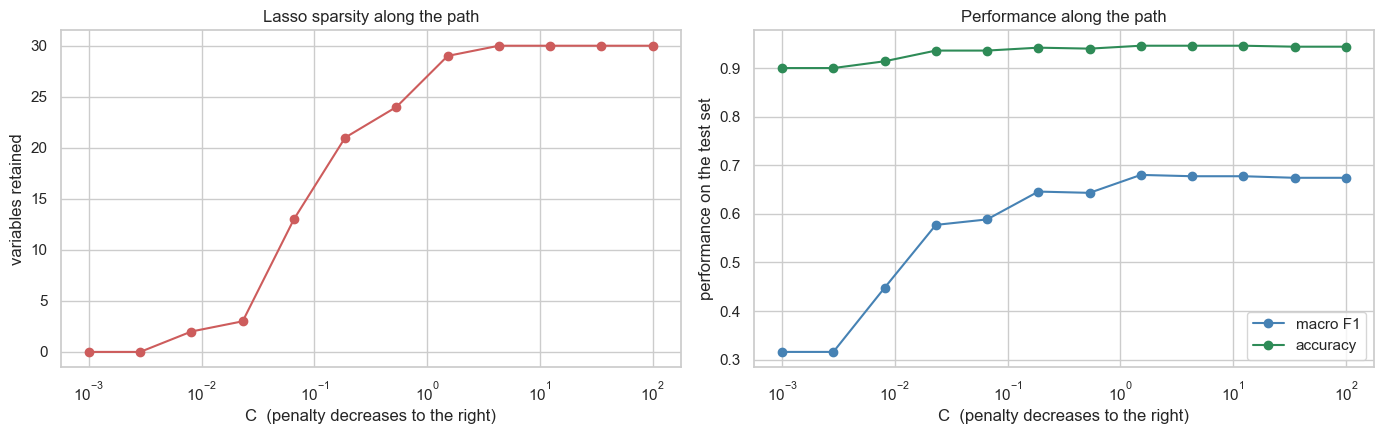

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

ax1.plot(path_results['C'], path_results['variables retained'], 'o-', color='indianred')
ax1.set_xscale('log'); ax1.set_xlabel('C  (penalty decreases to the right)')
ax1.set_ylabel('variables retained')
ax1.set_title('Lasso sparsity along the path')

ax2.plot(path_results['C'], path_results['macro F1'], 'o-', color='steelblue',
         label='macro F1')
ax2.plot(path_results['C'], path_results['accuracy'], 'o-', color='seagreen',
         label='accuracy')
ax2.set_xscale('log'); ax2.set_xlabel('C  (penalty decreases to the right)')
ax2.set_ylabel('performance on the test set')
ax2.set_title('Performance along the path'); ax2.legend()

plt.tight_layout(); plt.show()

**Conclusions:** The path shows clearly the trade-off between simplicity and performance.

With a very strong penalty, `C` equal to 0.001, every coefficient is zeroed and the model collapses
into predicting the majority class, with a macro F1 of 0.3158. As `C` increases, the variables enter in
order of importance: two at `C` equal to 0.008, three at 0.023, thirteen at 0.066, twenty-one at 0.187
and all of them from `C` equal to 4.33 onwards.

Performance rises quickly and then levels off. With thirteen variables the macro F1 reaches 0.5885, and
with twenty-one it reaches 0.6458, the maximum being 0.6801.

## 5. Choosing C by cross-validation

The previous section evaluated each `C` on the test set, which is useful to illustrate the behaviour
but is not appropriate for choosing the hyperparameter, since it would use the test data in the
decision.

The correct choice is made by **stratified 5-fold cross-validation**, applied only to the training set.
For each value of `C`, the model is fitted five times, leaving one fold out each time, and the mean of
the macro F1 obtained on the held-out folds is recorded.

The loop is written out explicitly for an important reason. **Standardization has to be done inside
each fold**, fitting the scaler only on the four training folds and applying it to the validation fold.
If the means and standard deviations were computed over the whole training set, the validation fold
would contribute to the statistics used by its own model, which constitutes information leakage. The
test set is only used at the end, for independent verification.

In [5]:
def evaluate_cv(l1_ratio, C, X_train_df, y_train_series, class_weight=None):
    """Stratified cross-validation, standardizing inside each fold."""
    scores = []
    for idx_train, idx_val in cv.split(X_train_df, y_train_series):
        X_a = X_train_df.iloc[idx_train]
        X_b = X_train_df.iloc[idx_val]
        y_a = y_train_series.iloc[idx_train]
        y_b = y_train_series.iloc[idx_val]

        fold_scaler = StandardScaler()
        X_a_scaled = fold_scaler.fit_transform(X_a)
        X_b_scaled = fold_scaler.transform(X_b)

        model = LogisticRegression(solver='saga', l1_ratio=l1_ratio, C=C,
                                   max_iter=10000, class_weight=class_weight,
                                   random_state=RANDOM_STATE)
        model.fit(X_a_scaled, y_a)
        scores.append(f1_score(y_b, model.predict(X_b_scaled), average='macro'))
    return float(np.mean(scores)), float(np.std(scores))

def tune(l1_ratio, X_train_df, class_weight=None):
    """Sweeps the C grid, picks the best value and refits on the full training set."""
    evaluations = [(C,) + evaluate_cv(l1_ratio, C, X_train_df, y_train, class_weight)
                   for C in C_GRID]
    best_C, mean_score, std_score = max(evaluations, key=lambda row: row[1])

    final_scaler = StandardScaler()
    X_scaled = final_scaler.fit_transform(X_train_df)
    model = LogisticRegression(solver='saga', l1_ratio=l1_ratio, C=best_C,
                               max_iter=10000, class_weight=class_weight,
                               random_state=RANDOM_STATE).fit(X_scaled, y_train)
    return {'C': best_C, 'f1_cv': mean_score, 'std_cv': std_score,
            'model': model, 'scaler': final_scaler}

def summary_of(fit_result, name, X_test_df, column_names, k):
    predicted = fit_result['model'].predict(
        fit_result['scaler'].transform(X_test_df))
    recalls = recall_score(y_test, predicted, average=None, labels=classes)
    _, _, n_columns = retained_variables(fit_result['model'], column_names)
    return {'model': name, 'k': k, 'C*': fit_result['C'],
            'macro F1 (CV)': fit_result['f1_cv'],
            'std (CV)': fit_result['std_cv'],
            'macro F1 (test)': f1_score(y_test, predicted, average='macro'),
            'accuracy': accuracy_score(y_test, predicted),
            'balanced acc': balanced_accuracy_score(y_test, predicted),
            'non-zero columns': n_columns,
            **{f'recall {c}': r for c, r in zip(classes, recalls)}}

fits = {name: tune(ratio, X_train) for name, ratio in MODELS}

pd.DataFrame([summary_of(f, name, X_test, columns, len(num_cols) + len(cat_cols))
              for name, f in fits.items()]).set_index('model')

,k,C*,macro F1 (CV),std (CV),macro F1 (test),accuracy,balanced acc,non-zero columns,recall DI_HT,recall DI_HY,recall HT
model,,,,,,,,,,,
Ridge,30,1.5199,0.6185,0.0405,0.6774,0.9460,0.6539,40,0.1429,0.9911,0.8276
Lasso,30,4.3288,0.6232,0.0416,0.6774,0.9460,0.6539,40,0.1429,0.9911,0.8276
Elastic Net,30,1.5199,0.6197,0.0381,0.6801,0.9460,0.6539,40,0.1429,0.9911,0.8276


**Conclusions:** Lasso obtains the best macro F1 in cross-validation, 0.6232, with `C` equal to 4.33.
Elastic Net reaches 0.6197 and Ridge 0.6185, both with `C` equal to 1.52. The differences between the
three are below 0.005, far below the variation across folds, so none is clearly superior to the others.

In all of them the chosen `C` corresponds to a weak penalty, and for that reason no variable is
eliminated. This happens because the penalty that maximizes performance is not strong enough to zero
coefficients. To obtain an effectively reduced set a stronger penalty must be imposed, which is done in
section 7.

## 6. Coefficients and selected variables

The coefficient magnitudes of the three penalties are compared at the chosen value of `C`. Since the
problem has three classes, the model estimates a coefficient matrix with one row per class.

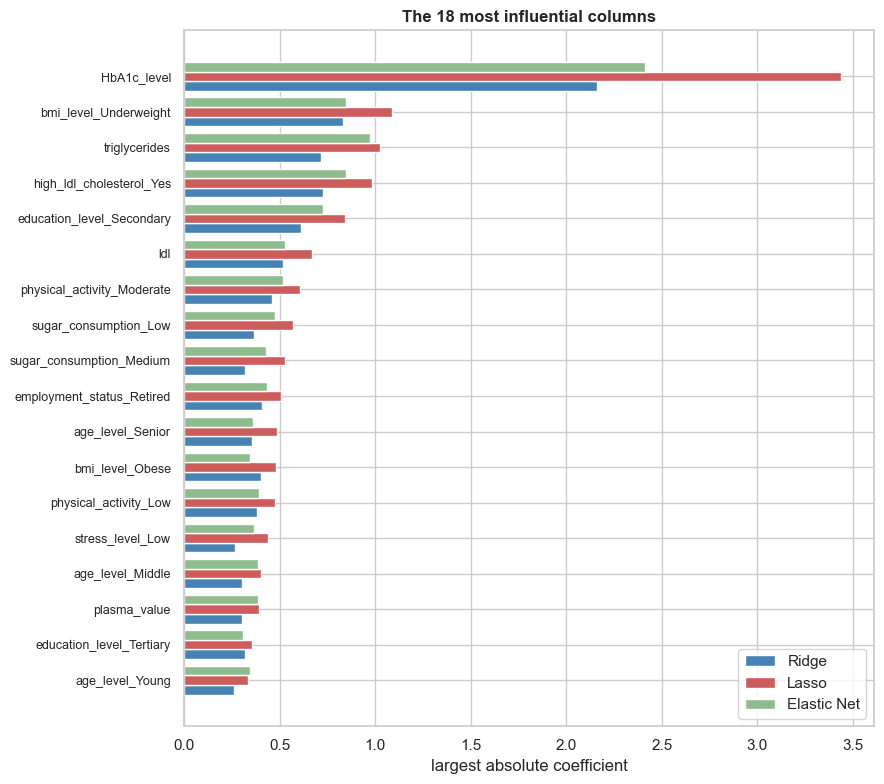

,Ridge,Lasso,Elastic Net
HbA1c_level,2.1618,3.4392,2.4106
bmi_level_Underweight,0.8295,1.0878,0.8462
triglycerides,0.7169,1.0273,0.9718
high_ldl_cholesterol_Yes,0.7257,0.9812,0.8485
education_level_Secondary,0.6108,0.8429,0.7276
ldl,0.5195,0.6716,0.5290
physical_activity_Moderate,0.4578,0.6064,0.5166
sugar_consumption_Low,0.3645,0.5687,0.4755
sugar_consumption_Medium,0.3209,0.5275,0.4291
employment_status_Retired,0.4088,0.5087,0.4315


In [6]:
coef_table = pd.DataFrame(
    {name: magnitudes(f['model']) for name, f in fits.items()},
    index=columns
).sort_values('Lasso', ascending=False)

fig, ax = plt.subplots(figsize=(9, 8))
top = coef_table.head(18).iloc[::-1]
position = np.arange(len(top))
for offset, name, color in [(-0.27, 'Ridge', 'steelblue'),
                            (0.0, 'Lasso', 'indianred'),
                            (0.27, 'Elastic Net', 'darkseagreen')]:
    ax.barh(position + offset, top[name], height=0.27, label=name, color=color)
ax.set_yticks(position); ax.set_yticklabels(top.index, fontsize=9)
ax.set_xlabel('largest absolute coefficient')
ax.set_title('The 18 most influential columns', weight='bold'); ax.legend()
plt.tight_layout(); plt.show()

coef_table.round(4).head(12)

**Conclusions:** The three penalties agree on the ordering. The variable `HbA1c_level` dominates
clearly, followed by indicators derived from the body mass index and by `triglycerides`.

This hierarchy coincides with the one the exploratory analysis had established statistically, through
the Kruskal-Wallis tests, in which `HbA1c_level` and `triglycerides` showed the largest effect sizes.
Two independent methods identify the same variables as relevant.

## 7. Full set versus reduced sets

To address the comparison required by the assignment, the reduced sets used are those that Lasso itself
selects at stronger penalties, identified along the path of section 4. Two points are chosen, an
intermediate one with twenty-one variables and an aggressive one with thirteen, which makes it possible
to measure the cost of each degree of simplification.

Each set is evaluated with the three penalties, with `C` chosen again by cross-validation and the
standardization redone inside each fold, so that the comparison is fair.

In [7]:
def columns_of_variables(variables_num, variables_cat):
    """Encoded columns corresponding to a set of original variables."""
    return [c for c in columns
            if c in variables_num or any(c.startswith(k + '_') for k in variables_cat)]

def lasso_selection(C):
    model = LogisticRegression(solver='saga', l1_ratio=1.0, C=C,
                               max_iter=10000, random_state=RANDOM_STATE)
    model.fit(X_train_scaled, y_train)
    kept_num, kept_cat, _ = retained_variables(model, columns)
    return kept_num, kept_cat

red21_num, red21_cat = lasso_selection(0.1874)
red13_num, red13_cat = lasso_selection(0.0658)

FEATURE_SETS = {
    'Full': (num_cols, cat_cols),
    'Reduced (21)': (red21_num, red21_cat),
    'Reduced (13)': (red13_num, red13_cat),
}

print('Reduced set with 13 variables:')
print(' ', sorted(red13_num + red13_cat))
print('\nEliminated in the 21-variable set:')
print(' ', sorted(set(num_cols + cat_cols) - set(red21_num + red21_cat)))

comparison_rows = []
for name, (v_num, v_cat) in FEATURE_SETS.items():
    set_columns = columns_of_variables(v_num, v_cat)
    for label, ratio in MODELS:
        fit_result = tune(ratio, X_train[set_columns])
        comparison_rows.append(summary_of(fit_result, f'{name} | {label}',
                                          X_test[set_columns], set_columns,
                                          len(v_num) + len(v_cat)))

results = pd.DataFrame(comparison_rows).set_index('model')
results.round(4)

Reduced set with 13 variables:
  ['HbA1c_level', 'age', 'age_level', 'blood_pressure', 'bmi_level', 'crp_level', 'employment_status', 'ldl_alternative', 'low_hdl_cholesterol', 'plasma_value', 'smoking', 'sugar_consumption', 'triglycerides']

Eliminated in the 21-variable set:
  ['alcohol_intake', 'cholesterol', 'diastolic_bp', 'gender', 'hdl', 'heart_rate', 'ldl', 'salt_intake', 'systolic_bp']


,k,C*,macro F1 (CV),std (CV),macro F1 (test),accuracy,balanced acc,non-zero columns,recall DI_HT,recall DI_HY,recall HT
model,,,,,,,,,,,
Full | Ridge,30,1.5199,0.6185,0.0405,0.6774,0.9460,0.6539,40,0.1429,0.9911,0.8276
Full | Lasso,30,4.3288,0.6232,0.0416,0.6774,0.9460,0.6539,40,0.1429,0.9911,0.8276
Full | Elastic Net,30,1.5199,0.6197,0.0381,0.6801,0.9460,0.6539,40,0.1429,0.9911,0.8276
Reduced (21) | Ridge,21,1.5199,0.6021,0.0345,0.6553,0.9440,0.6380,31,0.0952,0.9911,0.8276
Reduced (21) | Lasso,21,4.3288,0.6022,0.0383,0.6553,0.9440,0.6380,31,0.0952,0.9911,0.8276
Reduced (21) | Elastic Net,21,1.5199,0.6051,0.0334,0.6553,0.9440,0.6380,31,0.0952,0.9911,0.8276
Reduced (13) | Ridge,13,0.1874,0.5907,0.0384,0.6679,0.9420,0.6416,20,0.1429,0.9889,0.7931
Reduced (13) | Lasso,13,1.5199,0.5948,0.0465,0.6405,0.9380,0.6250,20,0.0952,0.9867,0.7931
Reduced (13) | Elastic Net,13,0.5337,0.5948,0.0465,0.6431,0.9400,0.6257,20,0.0952,0.9889,0.7931


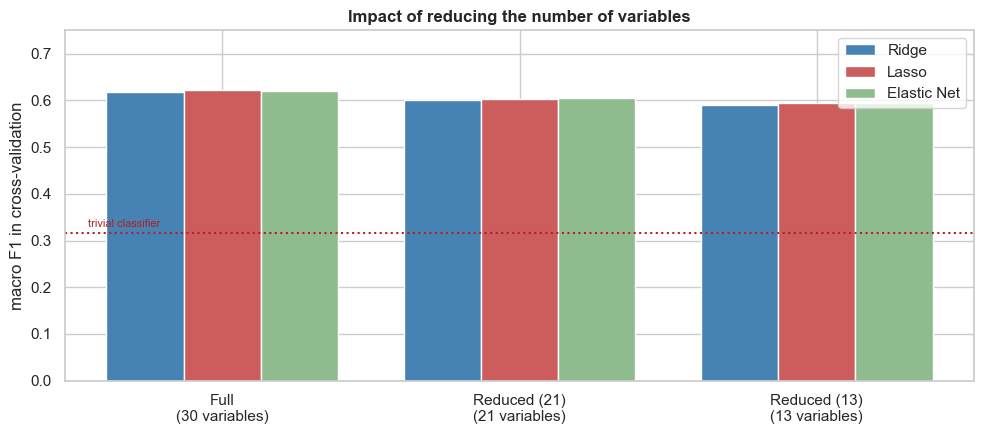

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.5))
width = 0.26
position = np.arange(len(FEATURE_SETS))
for offset, (label, _), color in zip([-width, 0, width], MODELS,
                                     ['steelblue', 'indianred', 'darkseagreen']):
    values = [results.loc[f'{name} | {label}', 'macro F1 (CV)'] for name in FEATURE_SETS]
    ax.bar(position + offset, values, width, label=label, color=color)
ax.set_xticks(position)
ax.set_xticklabels([f'{n}\n({len(FEATURE_SETS[n][0]) + len(FEATURE_SETS[n][1])} variables)'
                    for n in FEATURE_SETS])
ax.axhline(0.3158, ls=':', color='firebrick')
ax.text(-0.45, 0.33, 'trivial classifier', fontsize=8, color='firebrick')
ax.set_ylabel('macro F1 in cross-validation'); ax.set_ylim(0, 0.75)
ax.set_title('Impact of reducing the number of variables', weight='bold'); ax.legend()
plt.tight_layout(); plt.show()

**Conclusions:** Reducing the number of variables carries a small and progressive cost.

The full set of 30 variables reaches 0.6232 macro F1 in cross-validation. Reducing to 21 variables, the
best value falls to 0.6051, a loss of 0.018. Reducing to 13 variables, less than half of the original,
it falls to 0.5948, a total loss of 0.028.

A model with **43 per cent of the variables retains 95 per cent of the performance**. The three
penalties behave almost identically within each set, which is to be expected, since once the irrelevant
variables have been removed there is little difference left between shrinking coefficients and zeroing
them.

The 13-variable set includes `HbA1c_level`, `triglycerides`, `age` and `blood_pressure`, which the
exploratory analysis had identified as informative. It also includes `crp_level`, `plasma_value` and
`ldl_alternative`, which the statistical tests had not singled out. The case of `ldl_alternative`
deserves attention, since the exploratory analysis concluded that it is a random permutation of the
rows of `ldl`, with no link to the patient. Its survival shows that the penalty which optimizes
performance does not necessarily eliminate all the noise, and is an argument for always confronting
automatic selection with the prior statistical evidence.

## 8. Effect of class balancing

All the previous models obtain *accuracy* above 0.94 but balanced accuracy close to 0.65. The reason is
that they almost always get the majority class right and miss the minority one, because of the existing
imbalance, with around 90% of the records in a single class.

The `class_weight='balanced'` parameter weights each class by the inverse of its frequency, forcing the
model to give importance to the small classes.

This comparison uses the `lbfgs` algorithm with an L2 penalty, because `saga` does not converge when
`class_weight` is applied.

In [9]:
def evaluate_cv_lbfgs(C, class_weight):
    """The same manual cross-validation, with the lbfgs solver and L2 penalty."""
    scores = []
    for idx_train, idx_val in cv.split(X_train, y_train):
        fold_scaler = StandardScaler()
        X_a_scaled = fold_scaler.fit_transform(X_train.iloc[idx_train])
        X_b_scaled = fold_scaler.transform(X_train.iloc[idx_val])
        model = LogisticRegression(solver='lbfgs', l1_ratio=0.0, C=C, max_iter=10000,
                                   class_weight=class_weight,
                                   random_state=RANDOM_STATE)
        model.fit(X_a_scaled, y_train.iloc[idx_train])
        scores.append(f1_score(y_train.iloc[idx_val],
                               model.predict(X_b_scaled), average='macro'))
    return float(np.mean(scores))

weight_comparison = []
predictions = {}
for weight in (None, 'balanced'):
    best_C = max(C_GRID, key=lambda C: evaluate_cv_lbfgs(C, weight))
    f1_cv = evaluate_cv_lbfgs(best_C, weight)

    weight_scaler = StandardScaler()
    X_scaled = weight_scaler.fit_transform(X_train)
    model = LogisticRegression(solver='lbfgs', l1_ratio=0.0, C=best_C,
                               max_iter=10000, class_weight=weight,
                               random_state=RANDOM_STATE).fit(X_scaled, y_train)
    predicted = model.predict(weight_scaler.transform(X_test))
    recalls = recall_score(y_test, predicted, average=None, labels=classes)
    weight_comparison.append({
        'class_weight': str(weight), 'C*': best_C, 'macro F1 (CV)': f1_cv,
        'accuracy': accuracy_score(y_test, predicted),
        'balanced acc': balanced_accuracy_score(y_test, predicted),
        **{f'recall {c}': r for c, r in zip(classes, recalls)}})
    predictions[str(weight)] = predicted

pd.DataFrame(weight_comparison).set_index('class_weight').round(4)

,C*,macro F1 (CV),accuracy,balanced acc,recall DI_HT,recall DI_HY,recall HT
class_weight,,,,,,,
None,1.5199,0.6185,0.9460,0.6539,0.1429,0.9911,0.8276
balanced,0.1874,0.6108,0.7640,0.7421,0.6667,0.7667,0.7931


=== without balancing ===
              precision    recall  f1-score   support

       DI_HT     0.6000    0.1429    0.2308        21
       DI_HY     0.9571    0.9911    0.9738       450
          HT     0.8276    0.8276    0.8276        29

    accuracy                         0.9460       500
   macro avg     0.7949    0.6539    0.6774       500
weighted avg     0.9346    0.9460    0.9341       500

=== with class_weight='balanced' ===
              precision    recall  f1-score   support

       DI_HT     0.1157    0.6667    0.1972        21
       DI_HY     0.9914    0.7667    0.8647       450
          HT     0.7419    0.7931    0.7667        29

    accuracy                         0.7640       500
   macro avg     0.6163    0.7421    0.6095       500
weighted avg     0.9401    0.7640    0.8309       500



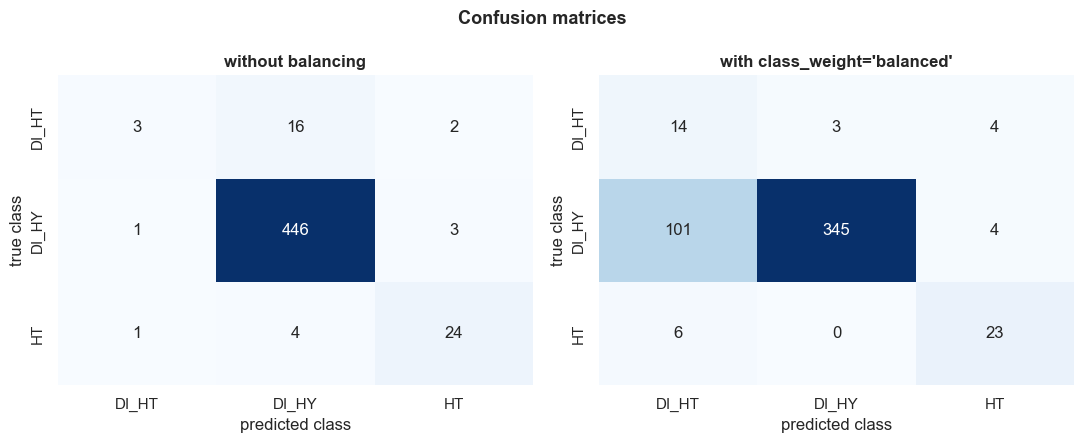

In [10]:
CONFIGURATIONS = [('None', 'without balancing'),
                  ('balanced', "with class_weight='balanced'")]

for label, title in CONFIGURATIONS:
    print(f'=== {title} ===')
    print(classification_report(y_test, predictions[label], labels=classes, digits=4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (label, title) in zip(axes, CONFIGURATIONS):
    matrix = confusion_matrix(y_test, predictions[label], labels=classes)
    sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=classes, yticklabels=classes, ax=ax)
    ax.set_xlabel('predicted class'); ax.set_ylabel('true class')
    ax.set_title(title, weight='bold')
fig.suptitle('Confusion matrices', fontsize=13, weight='bold')
plt.tight_layout(); plt.show()

**Conclusions:** Without compensation, the model reaches 0.9460 *accuracy* but only 0.14 recall on
class `DI_HT`. With `class_weight='balanced'`, the recall of `DI_HT` rises to 0.67 and the balanced
accuracy from 0.6539 to 0.7421, while *accuracy* falls to 0.7640.

The reading is that the second model is right fewer times overall, but spreads its correct predictions
across the three classes. Without compensation, out of the 21 actual occurrences of `DI_HT` the model
identifies only 3 and sends 16 to `DI_HY`. With compensation it identifies 14, but in exchange it
wrongly classifies 101 records of `DI_HY` as `DI_HT`. In other words, detecting 11 more cases of the
minority class costs around one hundred false positives.

In both configurations the errors concentrate on the separation between `DI_HT` and `DI_HY`, the two
classes whose overlap the exploratory analysis had already identified.

The gain in recall is reflected in a cost in precision, which falls to about 0.12 on class `DI_HT`. The
preferable configuration depends on the relative cost of the errors, information of a clinical nature
that the assignment does not provide.

## 9. Discussion

**The three penalties perform equivalently.** The differences in macro F1 between Ridge, Lasso and
Elastic Net stay below 0.01 in every set tested, a value lower than the variation across
cross-validation folds. The choice between them cannot be justified, in this problem, by performance.

**Ridge had no advantage to offer.** Its purpose is to stabilize coefficients when the predictors are
correlated. The exploratory analysis showed that, once the redundant columns were removed, the
correlations between variables are practically null, with variance inflation factors below 1.05. In
datasets where the predictors are strongly correlated, with inflation factors in the hundreds, Ridge
clearly outperforms the unregularized solution.

**The advantage of Lasso lies in interpretability, not in accuracy.** It is the only penalty that
systematically zeroes coefficients, and that is what makes it possible to build the reduced sets. The
gain does not show up in the metrics, but rather in the possibility of obtaining a model with thirteen
variables instead of thirty.

**The selection confirms the exploratory analysis.** The variables that survive the stronger penalties
include `HbA1c_level` and `triglycerides`, exactly those that the statistical tests had pointed to as
the most discriminative.

## 10. References

**Assignment and data**

- *Machine Learning (APRAU), Assignment*, ISEP, MEI, 2026/2027, version 1.0, section 5.
- `dataset_grupo_22.csv`, the 2000-record subset provided to group 22.

**Course lectures** (Elsa Ferreira Gomes, ISEP, 2026/2027)

- *T5, Linear Model Selection and Regularization: Ridge Regression, the Lasso and Elastic Net*,
  including the section on regularization applied to classification.
- *TP5, Example: Ridge, Lasso and Elastic net Regression*, practical worksheet consulted.
- *T4, Evaluation and Resampling*, for the stratified cross-validation.
- *Classification Metrics: Confusion Matrix and Beyond*, for the choice of metrics.

**Bibliography**

- James, G., Witten, D., Hastie, T., Tibshirani, R., *An Introduction to Statistical Learning with
  Python*, chapter 6.

**Previous work by the group**

- `notebooks/EDA_version3.ipynb`, the source of the removal of the redundant columns and of the
  expectations about which variables are informative.

**Libraries**

- pandas, NumPy, Matplotlib, seaborn and scikit-learn.